<a href="https://colab.research.google.com/github/hossain8078/Machine-Learning-and-Deep-Learning/blob/main/labs/Lab_6_CIFAR10_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Exercise 6: Image Classification with a CNN
Md Alamgir Hossain  
**Course:** ANLT-202 — Machine Learning and Deep Learning

## Objective and approach
Classify CIFAR-10 images using a Keras Sequential convolutional neural network. This solution follows all six instructions in the supplied Lab Exercise 6 and the import → prepare → build → compile → train → evaluate workflow in `06_Deep_Learning_Example.ipynb`. The example uses MNIST and Dense layers; this exercise requires CIFAR-10 and convolution/pooling layers.

**Run in Google Colab:** Upload this `.ipynb`, choose **Runtime → Change runtime type → T4 GPU** if available, then **Runtime → Run all**. No CSV or Drive mounting is needed: Keras downloads CIFAR-10 on the first run. Download access is required. CPU training can take considerably longer. If TensorFlow is missing outside Colab, install `tensorflow matplotlib numpy scikit-learn ipython`.

## 1. Import libraries and set reproducibility


In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
from IPython.display import display, Markdown

SEED = 42
EPOCHS = 10
BATCH_SIZE = 32
keras.utils.set_random_seed(SEED)
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11})
print('TensorFlow version:', tf.__version__)
print('GPU devices available:', len(tf.config.list_physical_devices('GPU')))
print(f'Seed: {SEED}; epochs: {EPOCHS}; batch size: {BATCH_SIZE}')


TensorFlow version: 2.21.0
GPU devices available: 0
Seed: 42; epochs: 10; batch size: 32


The TensorFlow version identifies the software used. A GPU count of zero means training uses the CPU; it does not mean the model is incorrect. The seed supports repeatability, although hardware and library differences can still change results. Ten epochs and batch size 32 match the instructor example.


## 2. Load CIFAR-10


In [2]:
# Use the exact dataset required by the exercise.
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
# Convert (N, 1) integer labels into a simple (N,) vector.
y_train = y_train.reshape(-1)
y_test = y_test.reshape(-1)
print('Training images:', X_train.shape, '| labels:', y_train.shape)
print('Test images:', X_test.shape, '| labels:', y_test.shape)
print('Original pixel range:', X_train.min(), 'to', X_train.max())
for label, name in enumerate(class_names):
    print(f'{label}: {name:10s} | training: {np.sum(y_train == label):,} | test: {np.sum(y_test == label):,}')
assert X_train.shape == (50000, 32, 32, 3)
assert X_test.shape == (10000, 32, 32, 3)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 957s 6us/step
Training images: (50000, 32, 32, 3) | labels: (50000,)
Test images: (10000, 32, 32, 3) | labels: (10000,)
Original pixel range: 0 to 255
0: airplane   | training: 5,000 | test: 1,000
1: automobile | training: 5,000 | test: 1,000
2: bird       | training: 5,000 | test: 1,000
3: cat        | training: 5,000 | test: 1,000
4: deer       | training: 5,000 | test: 1,000
5: dog        | training: 5,000 | test: 1,000
6: frog       | training: 5,000 | test: 1,000
7: horse      | training: 5,000 | test: 1,000
8: ship       | training: 5,000 | test: 1,000
9: truck      | training: 5,000 | test: 1,000


There are 50,000 training images and 10,000 test images, making 60,000 in total. Each image has 32 rows × 32 columns × 3 colour channels (red, green, blue). Each of the ten classes has 5,000 training and 1,000 test images. Labels 0–9 correspond to the class names printed above. The download bar, if shown, is data transfer progress.


## 3. Prepare the data: normalize pixels


In [3]:
# float32 uses less memory than float64; division maps pixels into [0, 1].
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0
print('Training pixel range:', X_train.min(), 'to', X_train.max())
print('Test pixel range:', X_test.min(), 'to', X_test.max())
print('Image data type:', X_train.dtype)
print('Labels remain integers:', y_train.dtype)
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_test.min() <= X_test.max() <= 1


Training pixel range: 0.0 to 1.0
Test pixel range: 0.0 to 1.0
Image data type: float32
Labels remain integers: uint8


Both pixel ranges are now 0.0–1.0, with float32 values. Dividing by 255 rescales colour intensity without changing the images' content or dimensions. Labels remain integers because the chosen loss accepts integer class IDs. Keep the RGB channels; do not flatten images before the convolution layers.


### 3.1. View sample images


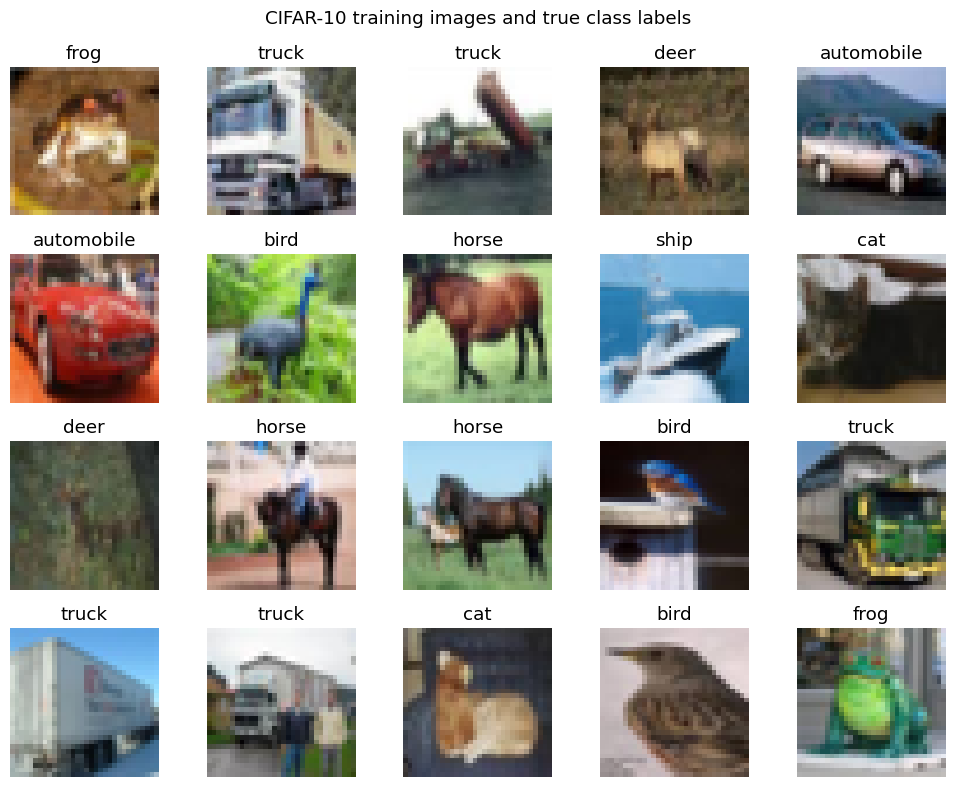

In [4]:
fig, axes = plt.subplots(4, 5, figsize=(10, 8))
for index, ax in enumerate(axes.flat):
    ax.imshow(X_train[index])
    ax.set_title(class_names[y_train[index]])
    ax.axis('off')
fig.suptitle('CIFAR-10 training images and true class labels')
plt.tight_layout()
plt.show()


These are the first 20 training images, labelled with their actual classes, not model predictions. Their blocky appearance is expected at 32×32 resolution. Different backgrounds, poses, and similar animal shapes help explain why this task can be difficult. This preview is not a performance assessment.


## 4. Build the CNN model


In [5]:
# Convolution preserves spatial structure while learning local visual patterns.
model = Sequential([
    Input(shape=(32, 32, 3)),
    Conv2D(32, (3, 3), activation='relu', name='conv_1'),
    MaxPooling2D((2, 2), name='pool_1'),
    Conv2D(64, (3, 3), activation='relu', name='conv_2'),
    MaxPooling2D((2, 2), name='pool_2'),
    Conv2D(64, (3, 3), activation='relu', name='conv_3'),
    Flatten(name='flatten'),
    Dense(64, activation='relu', name='dense_hidden'),
    Dense(10, activation='softmax', name='class_probabilities')
], name='cifar10_cnn')
model.summary()
assert model.count_params() == 122570


Model: "cifar10_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

`None` in the summary represents a variable batch size. With default valid padding, the feature shapes are **30×30×32 → 15×15×32 → 13×13×64 → 6×6×64 → 4×4×64 → 1,024 → 64 → 10**. Conv2D learns local filters; MaxPooling2D reduces spatial dimensions; Flatten converts the final feature maps into a vector; Dense layers combine these features for classification.

The model has **122,570 trainable parameters** before compilation/training. Pooling and Flatten have no learned parameters. For example, the first convolution has `(3×3×3 + 1)×32 = 896` parameters, including biases. ReLU adds nonlinearity; it helps gradient flow for positive activations but does not guarantee that gradients never vanish. The ten softmax outputs form a probability distribution, one value per class.


## 5. Compile the model


In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print('Compiled: Adam optimizer, sparse categorical cross-entropy, accuracy.')


Compiled: Adam optimizer, sparse categorical cross-entropy, accuracy.


Compilation configures learning; it does not train the network. Adam updates weights using gradients calculated by backpropagation. Sparse categorical cross-entropy is appropriate because labels are integers and each image belongs to one of ten classes. Accuracy is the fraction of images assigned the correct class. One-hot encoding is unnecessary with this loss.


## 6. Train the CNN


In [7]:
# Reserve 10% of the provided training set for validation, as in the example.
# Keras takes the last 5,000 images for validation before shuffling the rest.
# The original 10,000 test images are never passed to fit().
history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1,
    shuffle=True,
    verbose=2
)
display(Markdown(
    f"**Training result:** Completed {len(history.epoch)} epochs using 45,000 fitting images "
    f"and 5,000 validation images. Final training accuracy: **{history.history['accuracy'][-1]:.2%}**; "
    f"validation accuracy: **{history.history['val_accuracy'][-1]:.2%}**. "
    f"Final training loss: **{history.history['loss'][-1]:.4f}**; "
    f"validation loss: **{history.history['val_loss'][-1]:.4f}**."
))


Epoch 1/10
1407/1407 - 68s - 49ms/step - accuracy: 0.4512 - loss: 1.5089 - val_accuracy: 0.5624 - val_loss: 1.2458
Epoch 2/10
1407/1407 - 77s - 54ms/step - accuracy: 0.5924 - loss: 1.1525 - val_accuracy: 0.6246 - val_loss: 1.0502
Epoch 3/10
1407/1407 - 62s - 44ms/step - accuracy: 0.6523 - loss: 0.9948 - val_accuracy: 0.6574 - val_loss: 0.9771
Epoch 4/10
1407/1407 - 60s - 43ms/step - accuracy: 0.6878 - loss: 0.8952 - val_accuracy: 0.6694 - val_loss: 0.9274
Epoch 5/10
1407/1407 - 83s - 59ms/step - accuracy: 0.7134 - loss: 0.8252 - val_accuracy: 0.6804 - val_loss: 0.8994
Epoch 6/10
1407/1407 - 60s - 42ms/step - accuracy: 0.7324 - loss: 0.7687 - val_accuracy: 0.6756 - val_loss: 0.9166
Epoch 7/10
1407/1407 - 61s - 44ms/step - accuracy: 0.7497 - loss: 0.7219 - val_accuracy: 0.6816 - val_loss: 0.9494
Epoch 8/10
1407/1407 - 80s - 57ms/step - accuracy: 0.7649 - loss: 0.6771 - val_accuracy: 0.6778 - val_loss: 0.9762
Epoch 9/10
1407/1407 - 61s - 43ms/step - accuracy: 0.7790 - loss: 0.6353 - val_a

**Training result:** Completed 10 epochs using 45,000 fitting images and 5,000 validation images. Final training accuracy: **79.22%**; validation accuracy: **69.78%**. Final training loss: **0.5956**; validation loss: **0.9618**.

Each epoch is one pass through the 45,000 fitting images, with 1,407 batches per epoch (the final batch is smaller). `loss` and `accuracy` describe fitting performance; `val_loss` and `val_accuracy` describe validation performance without weight updates. Lower loss and higher accuracy generally indicate improvement. Epoch time measures runtime, not prediction quality. Training metrics are accumulated while weights change, whereas validation uses the weights at the end of the epoch; they are not measured under identical conditions.


### 6.1. Plot training and validation results


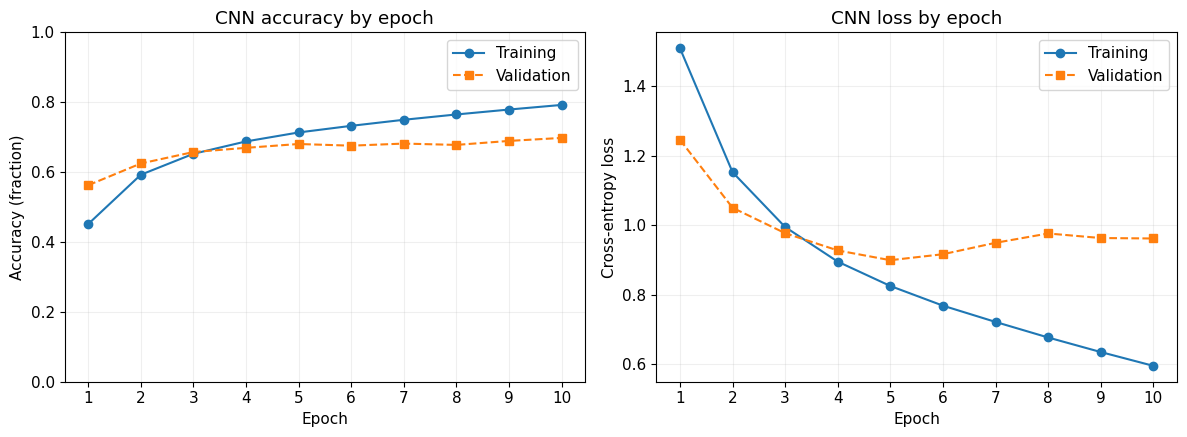

**Curve results:** Lowest validation loss occurred at epoch **5** (0.8994). The final training-minus-validation accuracy gap is **9.44 percentage points**. The model evaluated below uses the final epoch's weights; it does not automatically restore the best epoch.

In [8]:
epochs = np.arange(1, len(history.epoch) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for key, label, style in [('accuracy', 'Training', '-o'), ('val_accuracy', 'Validation', '--s')]:
    axes[0].plot(epochs, history.history[key], style, label=label)
axes[0].set(title='CNN accuracy by epoch', xlabel='Epoch', ylabel='Accuracy (fraction)')
axes[0].set_ylim(0, 1)
for key, label, style in [('loss', 'Training', '-o'), ('val_loss', 'Validation', '--s')]:
    axes[1].plot(epochs, history.history[key], style, label=label)
axes[1].set(title='CNN loss by epoch', xlabel='Epoch', ylabel='Cross-entropy loss')
for ax in axes:
    ax.set_xticks(epochs)
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()
best_epoch = int(np.argmin(history.history['val_loss']) + 1)
gap = history.history['accuracy'][-1] - history.history['val_accuracy'][-1]
display(Markdown(
    f"**Curve results:** Lowest validation loss occurred at epoch **{best_epoch}** "
    f"({min(history.history['val_loss']):.4f}). The final training-minus-validation "
    f"accuracy gap is **{gap * 100:.2f} percentage points**. "
    "The model evaluated below uses the final epoch's weights; it does not automatically restore the best epoch."
))


The left graph compares accuracy; the right compares loss. Look for training loss falling while validation loss rises over multiple epochs: that suggests overfitting. A training/validation gap alone does not prove it. If both accuracies remain low and both losses stay high, the model may be underfitting. Loss also considers the probability assigned to the correct class, so it can worsen even when accuracy changes little. If overfitting is observed, dropout or early stopping could be tested in a future validation-based experiment; no such improvement is claimed here.


## 7. Evaluate on the untouched test set


In [9]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
# Predict once; reuse these predictions for every detailed diagnostic.
y_pred_probs = model.predict(X_test, batch_size=128, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
correct = int(np.sum(y_pred == y_test))
assert np.isclose(test_acc, correct / len(y_test), atol=1e-6)
assert np.allclose(y_pred_probs.sum(axis=1), 1.0, atol=1e-5)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f} ({test_acc:.2%})')
print(f'Correct: {correct:,} / {len(y_test):,}; incorrect: {len(y_test)-correct:,}')
display(Markdown(
    f"**Test result:** The CNN correctly classified **{correct:,} of {len(y_test):,}** unseen test images "
    f"(**{test_acc:.2%}** accuracy), with loss **{test_loss:.4f}**. "
    f"This is **{(test_acc - 0.1)*100:.2f} percentage points** relative to a 10% uniform-random baseline."
))


Test loss: 0.9847
Test accuracy: 0.6853 (68.53%)
Correct: 6,853 / 10,000; incorrect: 3,147


**Test result:** The CNN correctly classified **6,853 of 10,000** unseen test images (**68.53%** accuracy), with loss **0.9847**. This is **58.53 percentage points** relative to a 10% uniform-random baseline.

Test accuracy is the lab's required final performance measure. For example, 0.70 would mean 70%, but the printed value above is the actual result from this run. Cross-entropy loss is not a percentage. The 10% baseline comes from choosing uniformly among ten classes; it is a reference, not a separately trained model. The test set was held out from training and validation. Avoid repeatedly tuning on its scores, which would weaken its role as an independent evaluation.


### 7.1. Classification report


In [10]:
print(classification_report(y_test, y_pred, labels=np.arange(10),
                            target_names=class_names, digits=3, zero_division=0))
report = classification_report(y_test, y_pred, labels=np.arange(10),
                               target_names=class_names, output_dict=True, zero_division=0)
best_class = max(class_names, key=lambda name: report[name]['recall'])
worst_class = min(class_names, key=lambda name: report[name]['recall'])
display(Markdown(
    f"**Class results:** Highest recall: **{best_class} ({report[best_class]['recall']:.2%})**; "
    f"lowest recall: **{worst_class} ({report[worst_class]['recall']:.2%})** "
    "(first class listed if tied). "
    f"Macro F1-score: **{report['macro avg']['f1-score']:.3f}**."
))


              precision    recall  f1-score   support

    airplane      0.787     0.635     0.703      1000
  automobile      0.903     0.706     0.792      1000
        bird      0.582     0.531     0.555      1000
         cat      0.571     0.433     0.493      1000
        deer      0.602     0.656     0.628      1000
         dog      0.581     0.632     0.606      1000
        frog      0.692     0.825     0.753      1000
       horse      0.706     0.753     0.729      1000
        ship      0.799     0.815     0.807      1000
       truck      0.675     0.867     0.759      1000

    accuracy                          0.685     10000
   macro avg      0.690     0.685     0.682     10000
weighted avg      0.690     0.685     0.682     10000



**Class results:** Highest recall: **truck (86.70%)**; lowest recall: **cat (43.30%)** (first class listed if tied). Macro F1-score: **0.682**.

Precision answers: “Of images predicted as this class, how many were correct?” Recall answers: “Of the actual images in this class, how many were found?” F1 balances precision and recall; support counts the true images (1,000 per test class). Macro averages weight classes equally; weighted averages use support. Since this test set has equal support per class, those averages match. Highest recall describes this measure specifically, not necessarily the best precision or F1.


### 7.2. Confusion matrix


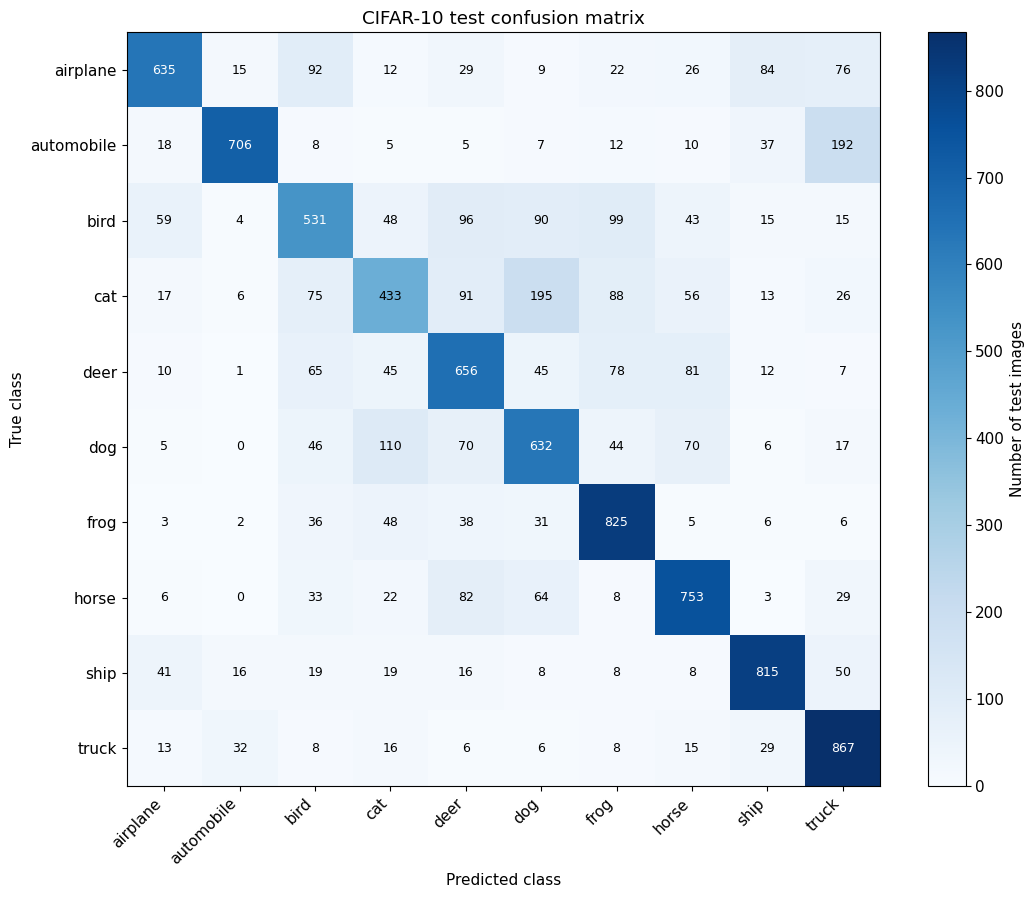

**Matrix result:** The largest directional confusion is actual **cat** predicted as **dog**, affecting **195 images** (19.50% of actual cat images). If counts tie, the first pair in matrix order is reported.

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(cm, cmap='Blues')
fig.colorbar(image, ax=ax, label='Number of test images')
ax.set(xticks=np.arange(10), yticks=np.arange(10),
       xticklabels=class_names, yticklabels=class_names,
       xlabel='Predicted class', ylabel='True class', title='CIFAR-10 test confusion matrix')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
for row in range(10):
    for col in range(10):
        ax.text(col, row, str(cm[row, col]), ha='center', va='center',
                color='white' if cm[row, col] > cm.max()/2 else 'black', fontsize=9)
plt.tight_layout()
plt.show()
errors = cm.copy()
np.fill_diagonal(errors, 0)
row, col = np.unravel_index(np.argmax(errors), errors.shape)
assert cm.sum() == 10000 and np.trace(cm) == correct
if errors.max() > 0:
    display(Markdown(
        f"**Matrix result:** The largest directional confusion is actual **{class_names[row]}** "
        f"predicted as **{class_names[col]}**, affecting **{errors[row, col]} images** "
        f"({errors[row, col]/cm[row].sum():.2%} of actual {class_names[row]} images). "
        "If counts tie, the first pair in matrix order is reported."
    ))
else:
    display(Markdown('**Matrix result:** All test predictions were correct.'))


**Output note:** Rows show the true class and columns show the predicted class. Diagonal cells are correct predictions; off-diagonal cells are errors. Each row totals 1,000 and the entire matrix totals 10,000. For example, the cat row/dog column counts actual cats labelled as dogs; the reverse error is a different cell. The named confusion above comes from the actual matrix rather than an assumed animal pair.


## 8. Inspect individual predictions


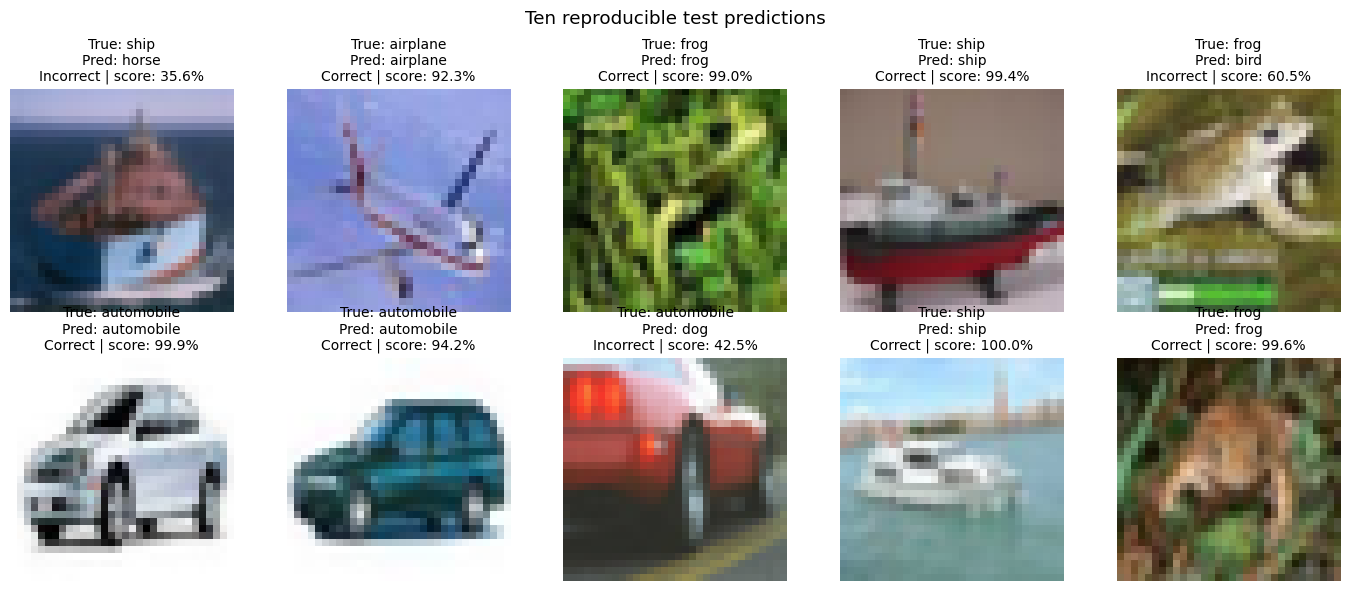

**Sample result:** **7 of 10** sampled images were classified correctly. The full 10,000-image test accuracy is the more reliable performance measure.

In [12]:
# A fixed random sample avoids selecting only successful examples.
indices = np.random.default_rng(SEED).choice(len(X_test), size=10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, idx in zip(axes.flat, indices):
    prediction = y_pred[idx]
    confidence = y_pred_probs[idx, prediction]
    outcome = 'Correct' if prediction == y_test[idx] else 'Incorrect'
    ax.imshow(X_test[idx])
    ax.set_title(f'True: {class_names[y_test[idx]]}\nPred: {class_names[prediction]}\n'
                 f'{outcome} | score: {confidence:.1%}', fontsize=10)
    ax.axis('off')
fig.suptitle('Ten reproducible test predictions')
plt.tight_layout()
plt.show()
sample_correct = int(np.sum(y_pred[indices] == y_test[indices]))
display(Markdown(
    f"**Sample result:** **{sample_correct} of 10** sampled images were classified correctly. "
    "The full 10,000-image test accuracy is the more reliable performance measure."
))


“True” is the dataset label and “Pred” is the model's chosen class. “Score” is the largest softmax output. A large score does not guarantee correctness and is not a calibrated probability of reliability. Correct/Incorrect text makes the result readable without relying on colour. Individual mistakes can illustrate the model's limitations but cannot establish why a particular image was misclassified.


## 9. Final result summary


In [13]:
display(Markdown(
    f"### Findings from this run\n"
    f"- **Task:** Ten-class classification of 32×32 RGB CIFAR-10 images.\n"
    f"- **Data:** 45,000 fitting, 5,000 validation, and 10,000 held-out test images; pixels normalized to [0, 1].\n"
    f"- **Model:** Three Conv2D layers, two MaxPooling2D layers, Flatten, Dense(64), and Dense(10, softmax).\n"
    f"- **Training:** Adam, sparse categorical cross-entropy, {len(history.epoch)} epochs, batch size {BATCH_SIZE}.\n"
    f"- **Final test accuracy:** **{test_acc:.2%}** ({correct:,}/10,000 correct); **test loss:** {test_loss:.4f}.\n"
    f"- **Class recall:** Highest: {best_class} ({report[best_class]['recall']:.2%}); "
    f"lowest: {worst_class} ({report[worst_class]['recall']:.2%}).\n"
    f"- **Generalization check:** Final training–validation accuracy gap: {gap*100:.2f} percentage points; "
    f"lowest validation loss at epoch {best_epoch}.\n"
    "- **Conclusion:** The CNN learns visual features directly from pixels. Its measured test performance and "
    "class errors above describe this run; they do not establish performance on new real-world image sources."
))


### Findings from this run
- **Task:** Ten-class classification of 32×32 RGB CIFAR-10 images.
- **Data:** 45,000 fitting, 5,000 validation, and 10,000 held-out test images; pixels normalized to [0, 1].
- **Model:** Three Conv2D layers, two MaxPooling2D layers, Flatten, Dense(64), and Dense(10, softmax).
- **Training:** Adam, sparse categorical cross-entropy, 10 epochs, batch size 32.
- **Final test accuracy:** **68.53%** (6,853/10,000 correct); **test loss:** 0.9847.
- **Class recall:** Highest: truck (86.70%); lowest: cat (43.30%).
- **Generalization check:** Final training–validation accuracy gap: 9.44 percentage points; lowest validation loss at epoch 5.
- **Conclusion:** The CNN learns visual features directly from pixels. Its measured test performance and class errors above describe this run; they do not establish performance on new real-world image sources.

This summary uses variables calculated in earlier cells, so its class names and numerical results agree with the evaluation. A single run does not measure variation across random seeds. Future experiments could compare dropout, early stopping, or training duration using validation data; these are suggestions, not completed comparisons.